Import libraries and load a sample

In [8]:
from pathlib import Path
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Project paths
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "experiments" else Path.cwd()

IMAGE_DIR = PROJECT_DIR / "data"
REFERENCE_DIR = PROJECT_DIR / "outputs/egg_segmentation/combined"

# Find reference masks
reference_masks = sorted(REFERENCE_DIR.glob("*_combined.png"))

print("Reference masks found:", len(reference_masks))
print("First mask:", reference_masks[0].name if reference_masks else "None")

Reference masks found: 110
First mask: test__egg__not_damaged_101_jpg.rf.479d12a2b41a5ec6d718dcdabd14b0c9_combined.png


Load the image and reference mask

In [9]:
# Show actual image filenames in the dataset
image_files = [
    p for p in IMAGE_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
]

print("Total images found:", len(image_files))

for p in image_files[:10]:
    print(p.name)

Total images found: 110
not_damaged_102_jpg.rf.8d754cbc174c6cb6fb1b5c1929edcbb1.jpg
not_damaged_107_jpg.rf.8497e164672ad2319ef9ea157023304e.jpg
not_damaged_109_jpg.rf.4d74eb94b1d03ebd3e7c442e58699304.jpg
not_damaged_115_jpg.rf.5e04f25a50022be8a5f0dbcfe42bc26f.jpg
not_damaged_119_jpg.rf.6758625c4b939166ca105d0509fc569e.jpg
not_damaged_11_jpg.rf.95e1bc4944748cfd1a56fe23a42b6ae8.jpg
not_damaged_120_jpg.rf.dfe91ad8ce891c84e495a8d59bbe01f5.jpg
not_damaged_122_jpg.rf.b44d8e5a76cadeff9b2d8eaa85309d09.jpg
not_damaged_126_jpg.rf.2c3342cf9ca7ab55f6682ef198e98bbd.jpg
not_damaged_130_jpg.rf.7289d26d022f33aa74b3517f40d6a127.jpg


In [10]:
mask_path = reference_masks[0]

# Extract the original image stem from the reference mask filename
stem = mask_path.name.split("__", 2)[-1].replace("_combined.png", "")

# Match using the filename without its extension
matches = [p for p in image_files if p.stem == stem]

print("Reference mask:", mask_path.name)
print("Expected image stem:", stem)
print("Matching images:", len(matches))

if len(matches) == 1:
    image_path = matches[0]

    image = cv2.cvtColor(
        cv2.imread(str(image_path)), cv2.COLOR_BGR2RGB
    )

    reference_mask = cv2.imread(
        str(mask_path), cv2.IMREAD_GRAYSCALE
    )
    reference_mask = (reference_mask > 127).astype(np.uint8)

    print("Matched image:", image_path.name)
    print("Image shape:", image.shape)
    print("Mask shape:", reference_mask.shape)
else:
    print("Match failed. Check the filename formats.")

Reference mask: test__egg__not_damaged_101_jpg.rf.479d12a2b41a5ec6d718dcdabd14b0c9_combined.png
Expected image stem: not_damaged_101_jpg.rf.479d12a2b41a5ec6d718dcdabd14b0c9
Matching images: 1
Matched image: not_damaged_101_jpg.rf.479d12a2b41a5ec6d718dcdabd14b0c9.jpg
Image shape: (640, 640, 3)
Mask shape: (640, 640)


Visualize the reference

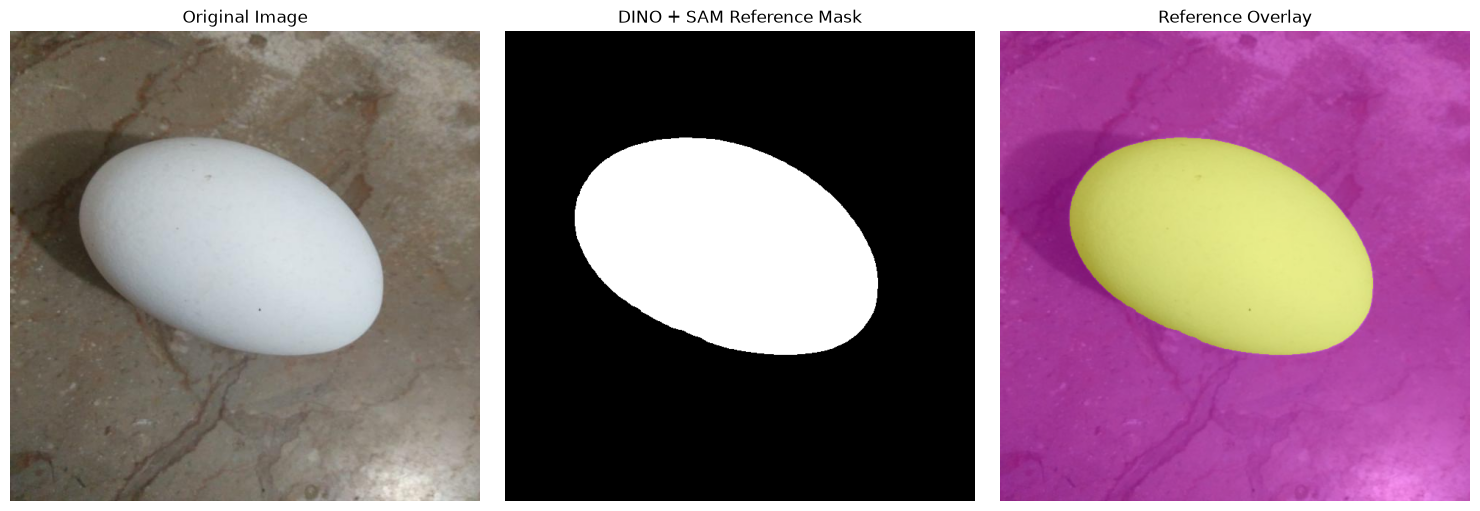

In [11]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(reference_mask, cmap="gray")
plt.title("DINO + SAM Reference Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image)
plt.imshow(reference_mask, cmap="spring", alpha=0.4)
plt.title("Reference Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

# Thresholding

### Otsu thresholding
we are going to try different classical algorithms  for segmentation

Otsu Binary: IoU=0.7475, Dice=0.8555
Otsu Inverse: IoU=0.0230, Dice=0.0450


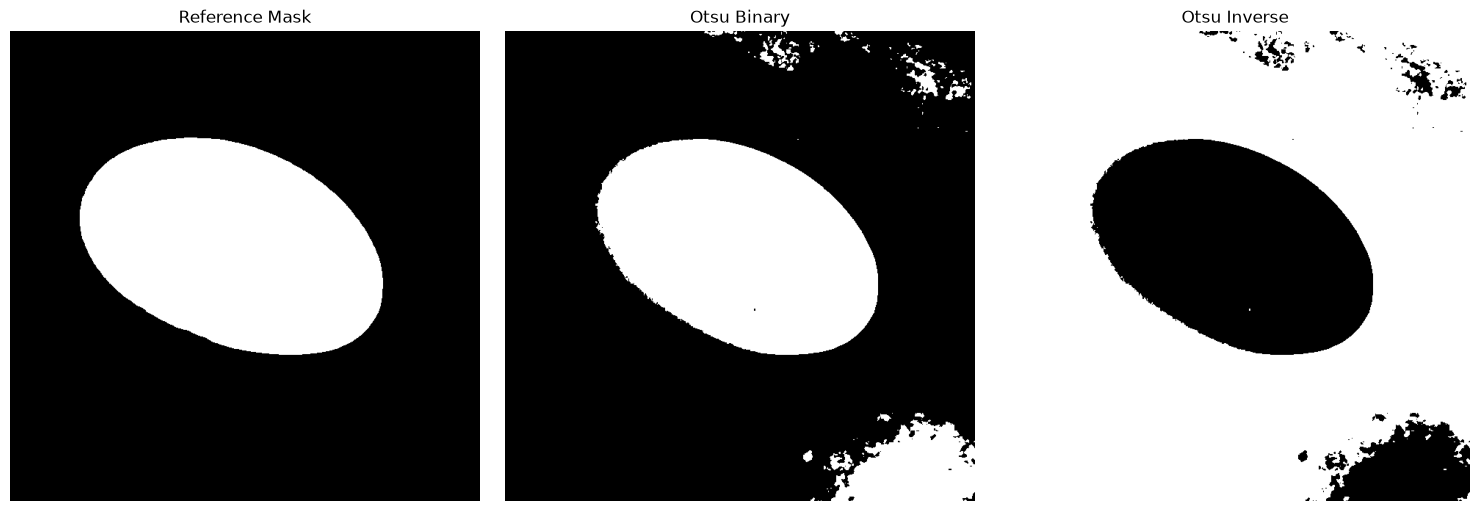

In [12]:
gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

# Otsu: bright regions become white
_, otsu_binary = cv2.threshold(
    gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Otsu: dark regions become white
_, otsu_inverse = cv2.threshold(
    gray, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

def calculate_metrics(prediction, reference):
    pred = prediction.astype(bool)
    ref = reference.astype(bool)

    intersection = np.logical_and(pred, ref).sum()
    union = np.logical_or(pred, ref).sum()

    iou = intersection / union if union else 1.0
    dice = (
        2 * intersection / (pred.sum() + ref.sum())
        if (pred.sum() + ref.sum()) else 1.0
    )

    return iou, dice

for name, mask in [
    ("Otsu Binary", otsu_binary),
    ("Otsu Inverse", otsu_inverse),
]:
    iou, dice = calculate_metrics(mask > 127, reference_mask)
    print(f"{name}: IoU={iou:.4f}, Dice={dice:.4f}")

plt.figure(figsize=(15, 5))

for i, (title, mask) in enumerate([
    ("Reference Mask", reference_mask),
    ("Otsu Binary", otsu_binary),
    ("Otsu Inverse", otsu_inverse),
]):
    plt.subplot(1, 3, i + 1)
    plt.imshow(mask, cmap="gray")
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

tring to improve the mask -> make it more clean 

Otsu + Morphology: IoU=0.8985, Dice=0.9466


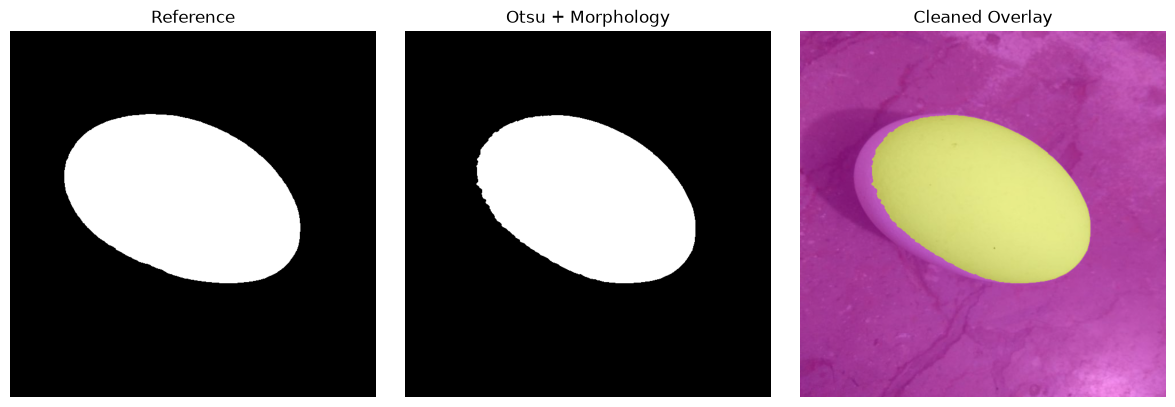

In [13]:
# Remove small noise and smooth the egg boundary
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))

cleaned_mask = cv2.morphologyEx(
    otsu_binary, cv2.MORPH_OPEN, kernel
)

cleaned_mask = cv2.morphologyEx(
    cleaned_mask, cv2.MORPH_CLOSE, kernel
)

# Keep only the largest connected foreground component
num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
    (cleaned_mask > 127).astype(np.uint8), connectivity=8
)

if num_labels > 1:
    largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    cleaned_mask = (labels == largest_label).astype(np.uint8) * 255

iou, dice = calculate_metrics(cleaned_mask > 127, reference_mask)

print(f"Otsu + Morphology: IoU={iou:.4f}, Dice={dice:.4f}")

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(reference_mask, cmap="gray")
plt.title("Reference")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cleaned_mask, cmap="gray")
plt.title("Otsu + Morphology")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image)
plt.imshow(cleaned_mask, cmap="spring", alpha=0.4)
plt.title("Cleaned Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

#### Adaptive thresholding

Adaptive + Morphology: IoU=0.2571, Dice=0.4090


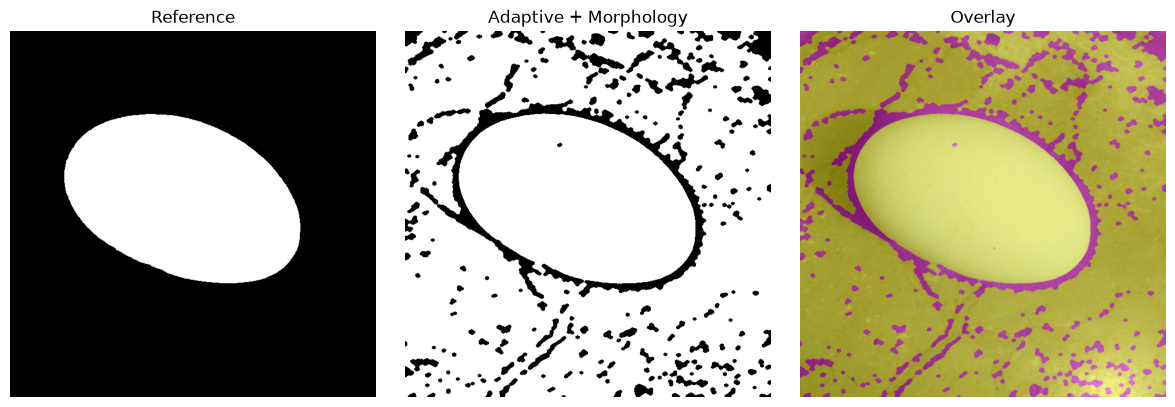

In [14]:
adaptive_mask = cv2.adaptiveThreshold(
    gray,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    51,   # Local neighborhood size
    5     # Threshold adjustment
)

# Clean noise and retain the largest component
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))

adaptive_clean = cv2.morphologyEx(
    adaptive_mask, cv2.MORPH_OPEN, kernel
)
adaptive_clean = cv2.morphologyEx(
    adaptive_clean, cv2.MORPH_CLOSE, kernel
)

num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
    (adaptive_clean > 127).astype(np.uint8), connectivity=8
)

if num_labels > 1:
    largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    adaptive_clean = (labels == largest_label).astype(np.uint8) * 255

iou, dice = calculate_metrics(adaptive_clean > 127, reference_mask)

print(f"Adaptive + Morphology: IoU={iou:.4f}, Dice={dice:.4f}")

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(reference_mask, cmap="gray")
plt.title("Reference")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(adaptive_clean, cmap="gray")
plt.title("Adaptive + Morphology")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image)
plt.imshow(adaptive_clean, cmap="spring", alpha=0.4)
plt.title("Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

**IoU and Dice score are low for this method -> adaptive + morphology poor segmentation -> we going to try to improve the first method using diffrent methods**

#### Gaussian Blur + Otsu + Morphology

Gaussian + Otsu + Morphology: IoU=0.8960, Dice=0.9451
Previous Otsu + Morphology:   IoU=0.8985, Dice=0.9466


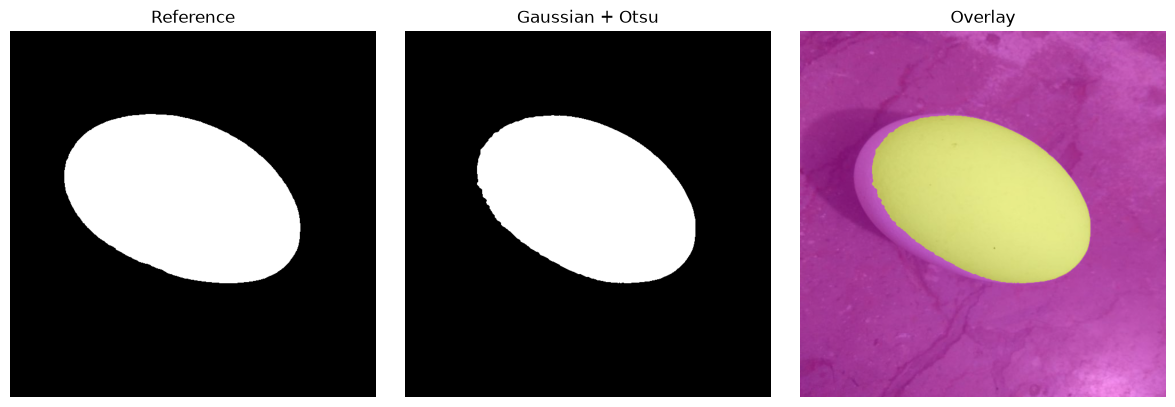

In [15]:
# Smooth the grayscale image before thresholding
gray_blur = cv2.GaussianBlur(gray, (5, 5), 0)

# Otsu thresholding
_, gaussian_otsu = cv2.threshold(
    gray_blur, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Morphological cleanup
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))

gaussian_clean = cv2.morphologyEx(
    gaussian_otsu, cv2.MORPH_OPEN, kernel
)
gaussian_clean = cv2.morphologyEx(
    gaussian_clean, cv2.MORPH_CLOSE, kernel
)

# Keep the largest connected component
num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
    (gaussian_clean > 127).astype(np.uint8),
    connectivity=8
)

if num_labels > 1:
    largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    gaussian_clean = (labels == largest_label).astype(np.uint8) * 255

# Evaluate
iou, dice = calculate_metrics(gaussian_clean > 127, reference_mask)

print(f"Gaussian + Otsu + Morphology: IoU={iou:.4f}, Dice={dice:.4f}")
print(f"Previous Otsu + Morphology:   IoU=0.8985, Dice=0.9466")

# Visualize
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(reference_mask, cmap="gray")
plt.title("Reference")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(gaussian_clean, cmap="gray")
plt.title("Gaussian + Otsu")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image)
plt.imshow(gaussian_clean, cmap="spring", alpha=0.4)
plt.title("Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()


very little improvement in IoU scores with Gaussian smoothing before Otsu thresholding and decrease in Dice score. This suggests that Gaussian smoothing may not be beneficial for this specific segmentation task, and the original Otsu + Morphology approach is already quite effective.

#### Median Blur + Otsu

Median + Otsu + Morphology: IoU=0.8968, Dice=0.9456
Baseline Otsu + Morphology: IoU=0.8985, Dice=0.9466


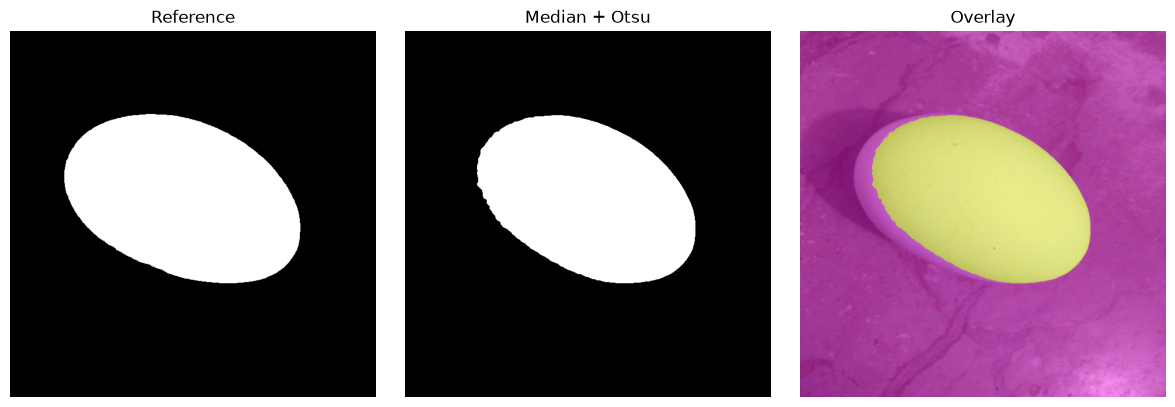

In [16]:
# Apply median blur
gray_median = cv2.medianBlur(gray, 5)

# Otsu thresholding
_, median_otsu = cv2.threshold(
    gray_median, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Morphological cleanup
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))

median_clean = cv2.morphologyEx(
    median_otsu, cv2.MORPH_OPEN, kernel
)
median_clean = cv2.morphologyEx(
    median_clean, cv2.MORPH_CLOSE, kernel
)

# Keep largest connected component
num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
    (median_clean > 127).astype(np.uint8), connectivity=8
)

if num_labels > 1:
    largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    median_clean = (labels == largest_label).astype(np.uint8) * 255

# Evaluate
iou, dice = calculate_metrics(median_clean > 127, reference_mask)

print(f"Median + Otsu + Morphology: IoU={iou:.4f}, Dice={dice:.4f}")
print("Baseline Otsu + Morphology: IoU=0.8985, Dice=0.9466")

# Visualize
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(reference_mask, cmap="gray")
plt.title("Reference")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(median_clean, cmap="gray")
plt.title("Median + Otsu")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image)
plt.imshow(median_clean, cmap="spring", alpha=0.4)
plt.title("Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

Still the same results as before. The baseline Otsu + Morphology method still outperforms the Gaussian and Median preprocessing methods in terms of IoU and Dice scores. 

#### Compare kernel sizes

Kernel 3x3: IoU=0.8993, Dice=0.9470
Kernel 5x5: IoU=0.8987, Dice=0.9467
Kernel 7x7: IoU=0.8985, Dice=0.9466
Kernel 9x9: IoU=0.8977, Dice=0.9461
Kernel 11x11: IoU=0.8975, Dice=0.9460

Best kernel by IoU: 3x3


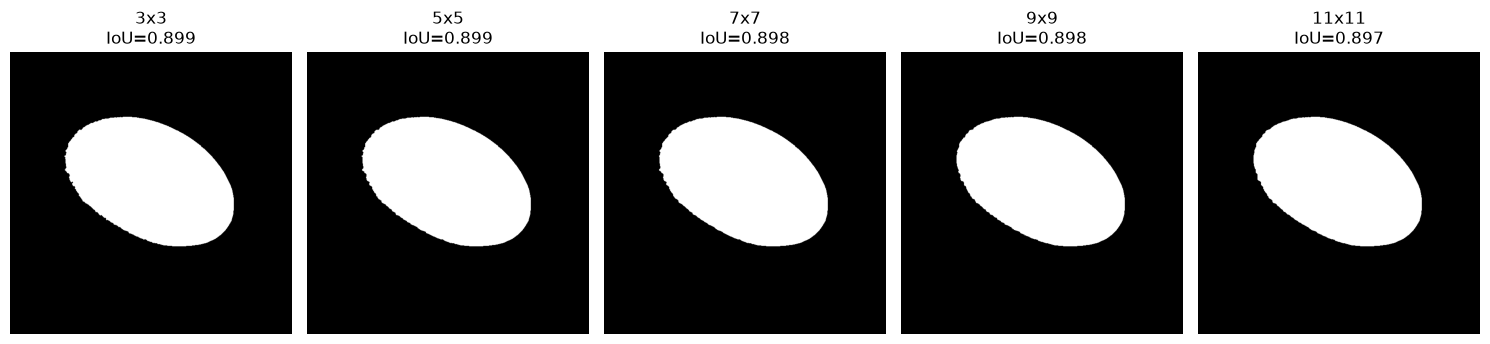

In [17]:
kernel_sizes = [3, 5, 7, 9, 11]
kernel_results = []

for size in kernel_sizes:
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (size, size)
    )

    # Start with the original Otsu mask
    cleaned = cv2.morphologyEx(
        otsu_binary, cv2.MORPH_OPEN, kernel
    )
    cleaned = cv2.morphologyEx(
        cleaned, cv2.MORPH_CLOSE, kernel
    )

    # Keep the largest connected component
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
        (cleaned > 127).astype(np.uint8), connectivity=8
    )

    if num_labels > 1:
        largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        cleaned = (labels == largest_label).astype(np.uint8) * 255

    iou, dice = calculate_metrics(cleaned > 127, reference_mask)

    kernel_results.append({
        "Kernel": f"{size}x{size}",
        "IoU": round(iou, 4),
        "Dice": round(dice, 4),
        "Mask": cleaned
    })

for result in kernel_results:
    print(
        f"Kernel {result['Kernel']}: "
        f"IoU={result['IoU']:.4f}, Dice={result['Dice']:.4f}"
    )

best_result = max(kernel_results, key=lambda x: x["IoU"])
print(f"\nBest kernel by IoU: {best_result['Kernel']}")

plt.figure(figsize=(15, 5))

for i, result in enumerate(kernel_results):
    plt.subplot(1, len(kernel_results), i + 1)
    plt.imshow(result["Mask"], cmap="gray")
    plt.title(
        f"{result['Kernel']}\n"
        f"IoU={result['IoU']:.3f}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

Lab L Binary: IoU=0.9073, Dice=0.9514
Lab L Inverse: IoU=0.0210, Dice=0.0412
Lab a Binary: IoU=0.0071, Dice=0.0140
Lab a Inverse: IoU=0.8691, Dice=0.9300
Lab b Binary: IoU=0.0091, Dice=0.0181
Lab b Inverse: IoU=0.9452, Dice=0.9718

Best Lab method: Lab b Inverse


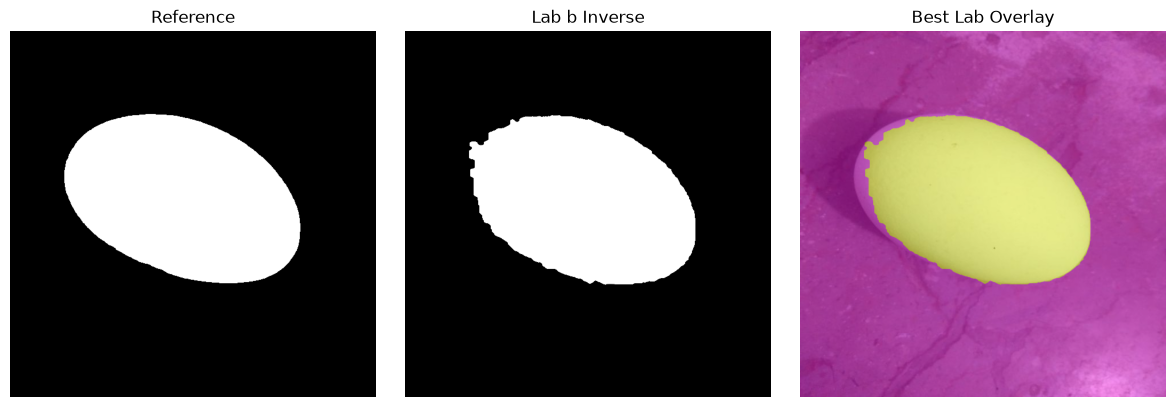

In [18]:
# Convert RGB image to Lab color space
lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)

# Apply Otsu to each Lab channel
lab_results = []

for channel_idx, channel_name in enumerate(["L", "a", "b"]):
    channel = lab[:, :, channel_idx]

    _, mask = cv2.threshold(
        channel, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Try both threshold polarities
    for polarity, candidate in [
        ("Binary", mask),
        ("Inverse", cv2.bitwise_not(mask))
    ]:
        kernel = cv2.getStructuringElement(
            cv2.MORPH_ELLIPSE, (7, 7)
        )

        cleaned = cv2.morphologyEx(
            candidate, cv2.MORPH_OPEN, kernel
        )
        cleaned = cv2.morphologyEx(
            cleaned, cv2.MORPH_CLOSE, kernel
        )

        num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
            (cleaned > 127).astype(np.uint8), connectivity=8
        )

        if num_labels > 1:
            largest_label = 1 + np.argmax(
                stats[1:, cv2.CC_STAT_AREA]
            )
            cleaned = (labels == largest_label).astype(np.uint8) * 255

        iou, dice = calculate_metrics(
            cleaned > 127, reference_mask
        )

        lab_results.append({
            "Method": f"Lab {channel_name} {polarity}",
            "IoU": iou,
            "Dice": dice,
            "Mask": cleaned
        })

for result in lab_results:
    print(
        f"{result['Method']}: "
        f"IoU={result['IoU']:.4f}, Dice={result['Dice']:.4f}"
    )

best_lab = max(lab_results, key=lambda x: x["IoU"])
print(f"\nBest Lab method: {best_lab['Method']}")

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(reference_mask, cmap="gray")
plt.title("Reference")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(best_lab["Mask"], cmap="gray")
plt.title(best_lab["Method"])
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image)
plt.imshow(best_lab["Mask"], cmap="spring", alpha=0.4)
plt.title("Best Lab Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

Evaluate Lab b Inverse with morphology

In [19]:
# Extract Lab b channel
lab = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
lab_b = lab[:, :, 2]

# Inverse Otsu thresholding
_, lab_b_mask = cv2.threshold(
    lab_b, 0, 255,
    cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
)

# Try several morphology kernel sizes
for size in [3, 5, 7, 9]:
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (size, size)
    )

    cleaned = cv2.morphologyEx(
        lab_b_mask, cv2.MORPH_OPEN, kernel
    )
    cleaned = cv2.morphologyEx(
        cleaned, cv2.MORPH_CLOSE, kernel
    )

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
        (cleaned > 127).astype(np.uint8), connectivity=8
    )

    if num_labels > 1:
        largest_label = 1 + np.argmax(
            stats[1:, cv2.CC_STAT_AREA]
        )
        cleaned = (labels == largest_label).astype(np.uint8) * 255

    iou, dice = calculate_metrics(cleaned > 127, reference_mask)

    print(
        f"Lab b Inverse + Morphology {size}x{size}: "
        f"IoU={iou:.4f}, Dice={dice:.4f}"
    )

Lab b Inverse + Morphology 3x3: IoU=0.9460, Dice=0.9722
Lab b Inverse + Morphology 5x5: IoU=0.9458, Dice=0.9721
Lab b Inverse + Morphology 7x7: IoU=0.9452, Dice=0.9718
Lab b Inverse + Morphology 9x9: IoU=0.9448, Dice=0.9716


Test on all 110 images

In [20]:
import re
import pandas as pd

results = []

kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (3, 3)
)

for mask_path in reference_masks:
    stem = mask_path.name.split("__", 2)[-1].replace(
        "_combined.png", ""
    )

    matches = [p for p in image_files if p.stem == stem]

    if len(matches) != 1:
        print(f"Skipping unmatched image: {stem}")
        continue

    img_bgr = cv2.imread(str(matches[0]))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    ref = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE)
    ref = ref > 127

    # Lab b channel + inverse Otsu
    lab = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)
    lab_b = lab[:, :, 2]

    _, pred = cv2.threshold(
        lab_b, 0, 255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    pred = cv2.morphologyEx(pred, cv2.MORPH_OPEN, kernel)
    pred = cv2.morphologyEx(pred, cv2.MORPH_CLOSE, kernel)

    # Keep the largest connected component
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
        (pred > 127).astype(np.uint8), connectivity=8
    )

    if num_labels > 1:
        largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        pred = labels == largest_label
    else:
        pred = np.zeros(ref.shape, dtype=bool)

    iou, dice = calculate_metrics(pred, ref)

    results.append({
        "image": matches[0].name,
        "IoU": iou,
        "Dice": dice
    })

df_lab = pd.DataFrame(results)

print("Images evaluated:", len(df_lab))
print(f"Mean IoU:  {df_lab['IoU'].mean():.4f}")
print(f"Mean Dice: {df_lab['Dice'].mean():.4f}")
print(f"Median IoU:  {df_lab['IoU'].median():.4f}")
print(f"Median Dice: {df_lab['Dice'].median():.4f}")
print(f"IoU below 0.50: {(df_lab['IoU'] < 0.50).sum()}")

Images evaluated: 110
Mean IoU:  0.2172
Mean Dice: 0.2975
Median IoU:  0.1326
Median Dice: 0.2341
IoU below 0.50: 95


Lab b Inverse works extremely well on our selected image but performs poorly across the dataset.

Compare methods across all images

In [21]:
df_otsu = []

kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (3, 3)
)

for mask_path in reference_masks:
    stem = mask_path.name.split("__", 2)[-1].replace(
        "_combined.png", ""
    )

    matches = [p for p in image_files if p.stem == stem]

    if len(matches) != 1:
        continue

    img = cv2.imread(str(matches[0]))
    gray_img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    ref = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE) > 127

    _, pred = cv2.threshold(
        gray_img, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    pred = cv2.morphologyEx(pred, cv2.MORPH_OPEN, kernel)
    pred = cv2.morphologyEx(pred, cv2.MORPH_CLOSE, kernel)

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
        (pred > 127).astype(np.uint8), connectivity=8
    )

    if num_labels > 1:
        largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        pred = labels == largest_label
    else:
        pred = np.zeros(ref.shape, dtype=bool)

    iou, dice = calculate_metrics(pred, ref)

    df_otsu.append({
        "image": matches[0].name,
        "IoU": iou,
        "Dice": dice
    })

df_otsu = pd.DataFrame(df_otsu)

print("Images evaluated:", len(df_otsu))
print(f"Mean IoU:  {df_otsu['IoU'].mean():.4f}")
print(f"Mean Dice: {df_otsu['Dice'].mean():.4f}")
print(f"Median IoU:  {df_otsu['IoU'].median():.4f}")
print(f"Median Dice: {df_otsu['Dice'].median():.4f}")
print(f"IoU below 0.50: {(df_otsu['IoU'] < 0.50).sum()}")

Images evaluated: 110
Mean IoU:  0.3470
Mean Dice: 0.4440
Median IoU:  0.2373
Median Dice: 0.3835
IoU below 0.50: 79


HSV Saturation + Otsu

In [22]:
df_hsv = []

kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (3, 3)
)

for mask_path in reference_masks:
    stem = mask_path.name.split("__", 2)[-1].replace(
        "_combined.png", ""
    )

    matches = [p for p in image_files if p.stem == stem]
    if len(matches) != 1:
        continue

    img = cv2.imread(str(matches[0]))
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    saturation = hsv[:, :, 1]

    ref = cv2.imread(
        str(mask_path), cv2.IMREAD_GRAYSCALE
    ) > 127

    _, binary = cv2.threshold(
        saturation, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    for polarity, candidate in [
        ("Binary", binary),
        ("Inverse", cv2.bitwise_not(binary))
    ]:
        pred = cv2.morphologyEx(
            candidate, cv2.MORPH_OPEN, kernel
        )
        pred = cv2.morphologyEx(
            pred, cv2.MORPH_CLOSE, kernel
        )

        num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
            (pred > 127).astype(np.uint8), connectivity=8
        )

        if num_labels > 1:
            largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
            pred = labels == largest
        else:
            pred = np.zeros(ref.shape, dtype=bool)

        iou, dice = calculate_metrics(pred, ref)

        df_hsv.append({
            "image": matches[0].name,
            "polarity": polarity,
            "IoU": iou,
            "Dice": dice
        })

df_hsv = pd.DataFrame(df_hsv)

for polarity in ["Binary", "Inverse"]:
    subset = df_hsv[df_hsv["polarity"] == polarity]
    print(f"\nHSV Saturation - {polarity}")
    print(f"Mean IoU:  {subset['IoU'].mean():.4f}")
    print(f"Mean Dice: {subset['Dice'].mean():.4f}")
    print(f"Median IoU: {subset['IoU'].median():.4f}")


HSV Saturation - Binary
Mean IoU:  0.0396
Mean Dice: 0.0620
Median IoU: 0.0012

HSV Saturation - Inverse
Mean IoU:  0.2648
Mean Dice: 0.3707
Median IoU: 0.1783


## K-means color segmentation

In [23]:
from sklearn.cluster import KMeans

df_kmeans = []

for mask_path in reference_masks:
    stem = mask_path.name.split("__", 2)[-1].replace(
        "_combined.png", ""
    )
    matches = [p for p in image_files if p.stem == stem]

    if len(matches) != 1:
        continue

    img = cv2.imread(str(matches[0]))
    rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    ref = cv2.imread(
        str(mask_path), cv2.IMREAD_GRAYSCALE
    ) > 127

    # Cluster RGB pixels into two groups
    pixels = rgb.reshape(-1, 3).astype(np.float32)

    kmeans = KMeans(
        n_clusters=2,
        random_state=42,
        n_init=3
    )
    labels = kmeans.fit_predict(pixels).reshape(ref.shape)

    # Evaluate both possible foreground clusters
    for cluster_id in [0, 1]:
        pred = labels == cluster_id

        # Keep the largest connected component
        num_labels, components, stats, _ = cv2.connectedComponentsWithStats(
            pred.astype(np.uint8), connectivity=8
        )

        if num_labels > 1:
            largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
            pred = components == largest
        else:
            pred = np.zeros(ref.shape, dtype=bool)

        iou, dice = calculate_metrics(pred, ref)

        df_kmeans.append({
            "image": matches[0].name,
            "cluster": cluster_id,
            "IoU": iou,
            "Dice": dice
        })

df_kmeans = pd.DataFrame(df_kmeans)

for cluster_id in [0, 1]:
    subset = df_kmeans[df_kmeans["cluster"] == cluster_id]
    print(f"\nK-means cluster {cluster_id}")
    print(f"Mean IoU:  {subset['IoU'].mean():.4f}")
    print(f"Mean Dice: {subset['Dice'].mean():.4f}")
    print(f"Median IoU: {subset['IoU'].median():.4f}")


K-means cluster 0
Mean IoU:  0.1781
Mean Dice: 0.2412
Median IoU: 0.0581

K-means cluster 1
Mean IoU:  0.2226
Mean Dice: 0.2837
Median IoU: 0.0489


### GrabCut segmentation
GrabCut uses foreground and background models plus spatial information, rather than relying only on a global threshold. It needs an initial foreground estimate, so we'll use the Otsu mask to initialize it.

GrabCut with Otsu initialization

GrabCut: IoU=0.9886, Dice=0.9943


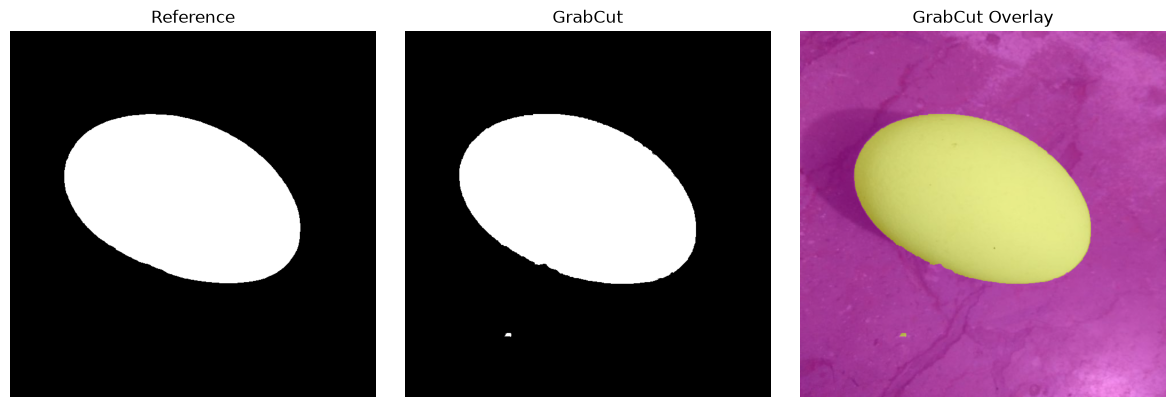

In [24]:
# Use the original image in BGR format for GrabCut
img_bgr = cv2.imread(str(image_path))

# Initialize with the Otsu mask
initial_mask = otsu_binary.copy()

grabcut_mask = np.where(
    initial_mask > 127,
    cv2.GC_PR_FGD,
    cv2.GC_PR_BGD
).astype(np.uint8)

# Mark a border as definite background
border = 10
grabcut_mask[:border, :] = cv2.GC_BGD
grabcut_mask[-border:, :] = cv2.GC_BGD
grabcut_mask[:, :border] = cv2.GC_BGD
grabcut_mask[:, -border:] = cv2.GC_BGD

bg_model = np.zeros((1, 65), np.float64)
fg_model = np.zeros((1, 65), np.float64)

cv2.grabCut(
    img_bgr,
    grabcut_mask,
    None,
    bg_model,
    fg_model,
    5,
    cv2.GC_INIT_WITH_MASK
)

grabcut_result = np.where(
    (grabcut_mask == cv2.GC_FGD) |
    (grabcut_mask == cv2.GC_PR_FGD),
    255,
    0
).astype(np.uint8)

iou, dice = calculate_metrics(
    grabcut_result > 127,
    reference_mask
)

print(f"GrabCut: IoU={iou:.4f}, Dice={dice:.4f}")

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(reference_mask, cmap="gray")
plt.title("Reference")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(grabcut_result, cmap="gray")
plt.title("GrabCut")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(image)
plt.imshow(grabcut_result, cmap="spring", alpha=0.4)
plt.title("GrabCut Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In [25]:
test_images = [
    p for p in image_files
    if p.relative_to(IMAGE_DIR).parts[0] == "test"
]

print("Test images:", len(test_images))

kernel = cv2.getStructuringElement(
    cv2.MORPH_ELLIPSE, (3, 3)
)

test_results = []

for image_path in test_images:
    # Match image to its reference mask
    stem = image_path.stem
    matching_masks = [
        p for p in reference_masks
        if p.name.endswith(f"{stem}_combined.png")
    ]

    if len(matching_masks) != 1:
        print("Skipping unmatched:", image_path.name)
        continue

    img_bgr = cv2.imread(str(image_path))
    gray_img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    ref = cv2.imread(
        str(matching_masks[0]), cv2.IMREAD_GRAYSCALE
    ) > 127

    # Otsu initialization
    _, otsu = cv2.threshold(
        gray_img, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    gc_mask = np.where(
        otsu > 127, cv2.GC_PR_FGD, cv2.GC_PR_BGD
    ).astype(np.uint8)

    # Mark image borders as definite background
    border = 10
    gc_mask[:border, :] = cv2.GC_BGD
    gc_mask[-border:, :] = cv2.GC_BGD
    gc_mask[:, :border] = cv2.GC_BGD
    gc_mask[:, -border:] = cv2.GC_BGD

    bg_model = np.zeros((1, 65), np.float64)
    fg_model = np.zeros((1, 65), np.float64)

    cv2.grabCut(
        img_bgr,
        gc_mask,
        None,
        bg_model,
        fg_model,
        5,
        cv2.GC_INIT_WITH_MASK
    )

    pred = np.isin(
        gc_mask, [cv2.GC_FGD, cv2.GC_PR_FGD]
    )

    # Remove small isolated components
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
        pred.astype(np.uint8), connectivity=8
    )

    if num_labels > 1:
        largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        pred = labels == largest

    iou, dice = calculate_metrics(pred, ref)

    test_results.append({
        "image": image_path.name,
        "IoU": iou,
        "Dice": dice
    })

df_grabcut_test = pd.DataFrame(test_results)

print("\nTest results")
print("Images evaluated:", len(df_grabcut_test))

if not df_grabcut_test.empty:
    print(f"Mean IoU:  {df_grabcut_test['IoU'].mean():.4f}")
    print(f"Mean Dice: {df_grabcut_test['Dice'].mean():.4f}")
    print(f"Median IoU:  {df_grabcut_test['IoU'].median():.4f}")
    print(f"Median Dice: {df_grabcut_test['Dice'].median():.4f}")

    display(df_grabcut_test.sort_values("IoU"))

Test images: 11

Test results
Images evaluated: 11
Mean IoU:  0.5119
Mean Dice: 0.5830
Median IoU:  0.3840
Median Dice: 0.5549


,image,IoU,Dice
6,not_damaged_1_jpg.rf.d74c98a14f068b48c1f58fd57...,0.000000,0.000000
1,not_damaged_125_jpg.rf.b19353b1f84dcbef1ec088b...,0.053898,0.102283
3,not_damaged_152_jpg.rf.a57edb18d395ce87e23f7ab...,0.121377,0.216478
7,not_damaged_30_jpg.rf.48e9261777355fe67139ac1c...,0.173726,0.296025
4,not_damaged_153_jpg.rf.ea842e70f08e63e69bbcc74...,0.296408,0.457276
9,not_damaged_4_jpg.rf.36c78b63ea4710d9642651ac3...,0.383976,0.554888
5,not_damaged_161_jpg.rf.fd216aa5e11e147fc152747...,0.793523,0.884876
10,not_damaged_78_jpg.rf.d3a6e8624d192abc58ff7df9...,0.916230,0.956284
2,not_damaged_14_jpg.rf.dc96559078b03433d2b65e50...,0.925249,0.961174
8,not_damaged_43_jpg.rf.66c31342150e751c30214786...,0.978070,0.988913


Instead of using Otsu to initialize GrabCut, let's use the largest foreground component from Otsu to create a probable-foreground region, with an inner core marked as definite foreground.

This should help GrabCut distinguish the egg from the background, especially when Otsu produces noisy regions.


GrabCut with an improved initialization

In [26]:
def grabcut_improved(img_bgr, iterations=5):
    gray_img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    # Otsu initialization
    _, otsu = cv2.threshold(
        gray_img, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Remove small noise
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (3, 3)
    )

    cleaned = cv2.morphologyEx(
        otsu, cv2.MORPH_OPEN, kernel
    )
    cleaned = cv2.morphologyEx(
        cleaned, cv2.MORPH_CLOSE, kernel
    )

    # Find the largest component
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(
        (cleaned > 127).astype(np.uint8), connectivity=8
    )

    if num_labels <= 1:
        return np.zeros(gray_img.shape, dtype=np.uint8)

    largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    component = (labels == largest).astype(np.uint8) * 255

    # Erode to obtain a more confident foreground core
    core = cv2.erode(component, kernel, iterations=2)

    # Initialize all pixels as probable background
    gc_mask = np.full(
        gray_img.shape, cv2.GC_PR_BGD, dtype=np.uint8
    )

    # Otsu's largest component becomes probable foreground
    gc_mask[component > 0] = cv2.GC_PR_FGD

    # Inner core becomes definite foreground
    gc_mask[core > 0] = cv2.GC_FGD

    # Image border is definite background
    border = 10
    gc_mask[:border, :] = cv2.GC_BGD
    gc_mask[-border:, :] = cv2.GC_BGD
    gc_mask[:, :border] = cv2.GC_BGD
    gc_mask[:, -border:] = cv2.GC_BGD

    bg_model = np.zeros((1, 65), np.float64)
    fg_model = np.zeros((1, 65), np.float64)

    cv2.grabCut(
        img_bgr,
        gc_mask,
        None,
        bg_model,
        fg_model,
        iterations,
        cv2.GC_INIT_WITH_MASK
    )

    result = np.isin(
        gc_mask, [cv2.GC_FGD, cv2.GC_PR_FGD]
    ).astype(np.uint8)

    return result

In [27]:
improved_results = []

for image_path in test_images:
    stem = image_path.stem

    matches = [
        p for p in reference_masks
        if p.name.endswith(f"{stem}_combined.png")
    ]

    if len(matches) != 1:
        continue

    img_bgr = cv2.imread(str(image_path))
    reference = cv2.imread(
        str(matches[0]), cv2.IMREAD_GRAYSCALE
    ) > 127

    prediction = grabcut_improved(img_bgr)

    # Keep the largest predicted component
    n, labels, stats, _ = cv2.connectedComponentsWithStats(
        prediction, connectivity=8
    )

    if n > 1:
        largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        prediction = (labels == largest).astype(np.uint8)

    iou, dice = calculate_metrics(prediction > 0, reference)

    improved_results.append({
        "image": image_path.name,
        "IoU": iou,
        "Dice": dice
    })

df_grabcut_improved = pd.DataFrame(improved_results)

print("Images evaluated:", len(df_grabcut_improved))
print(f"Mean IoU: {df_grabcut_improved['IoU'].mean():.4f}")
print(f"Mean Dice: {df_grabcut_improved['Dice'].mean():.4f}")
print(f"Median IoU: {df_grabcut_improved['IoU'].median():.4f}")
print(f"Median Dice: {df_grabcut_improved['Dice'].median():.4f}")

Images evaluated: 11
Mean IoU: 0.3615
Mean Dice: 0.4443
Median IoU: 0.2436
Median Dice: 0.3917


The improved initialization actually made GrabCut worse. The original method is still better on the test set.

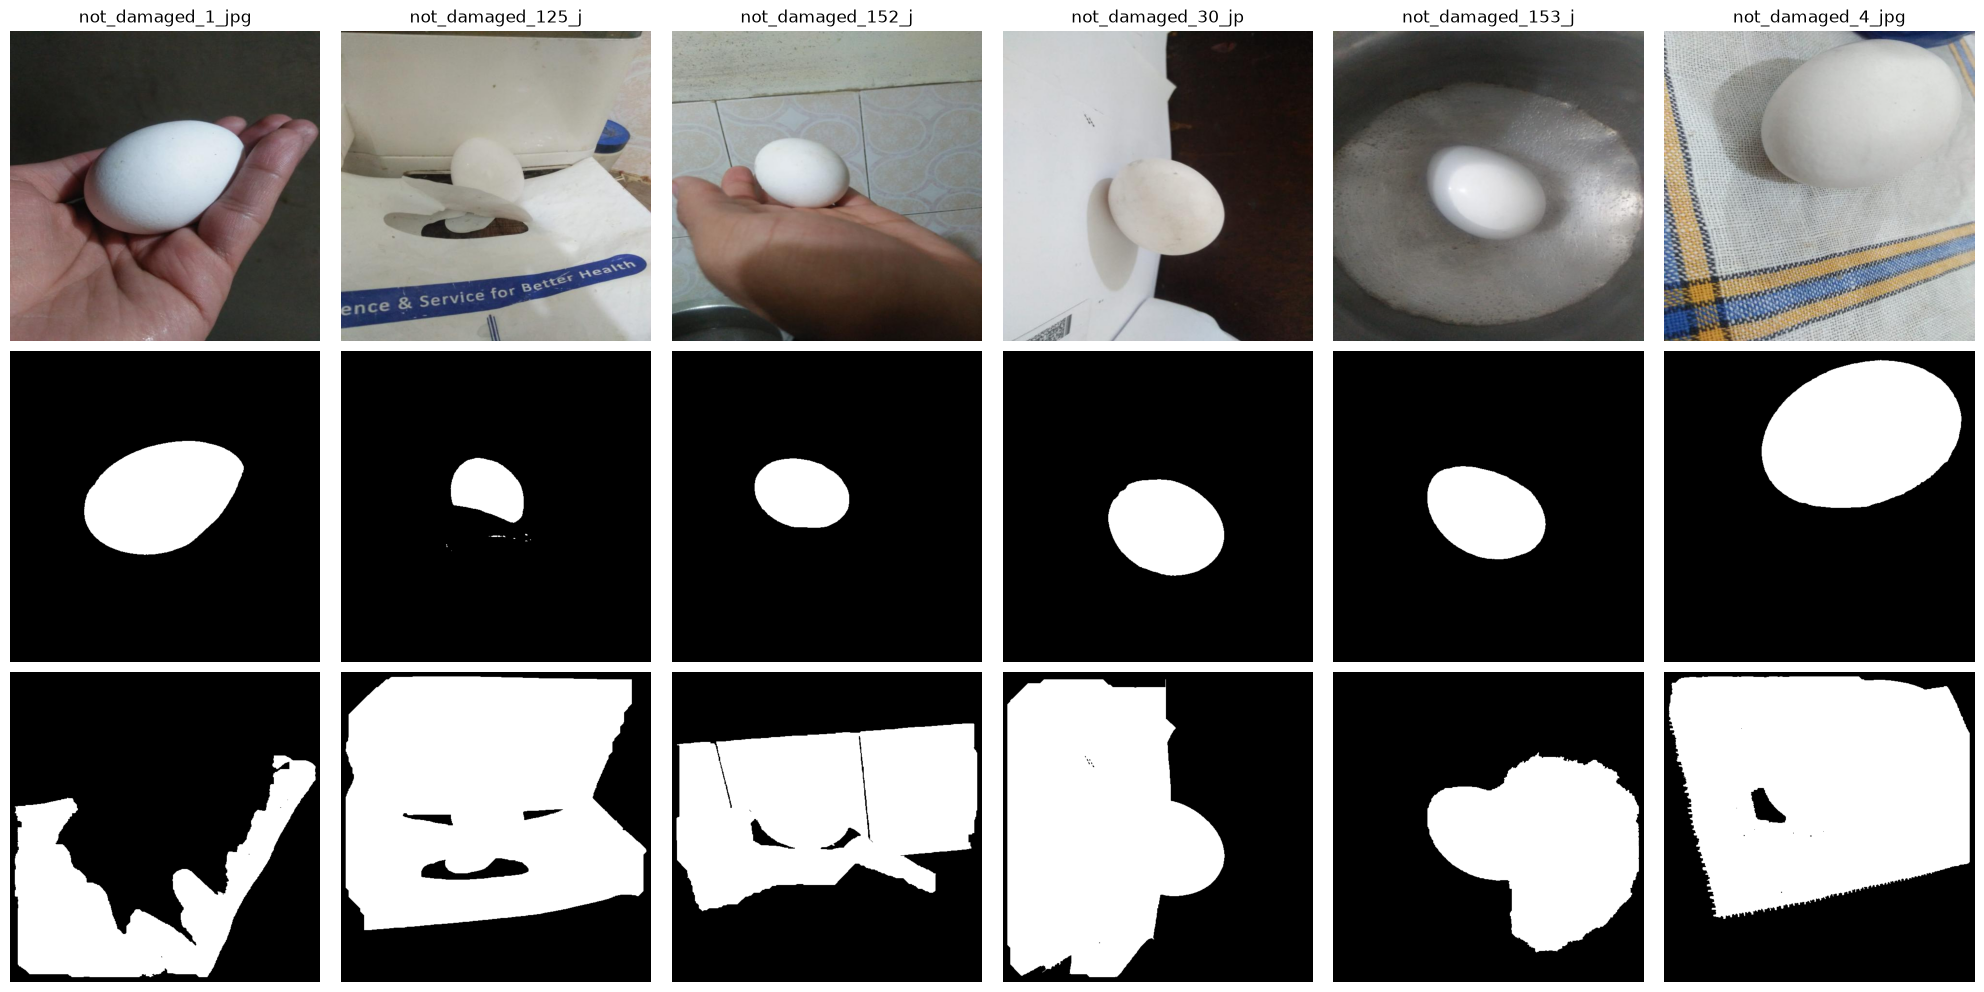

In [28]:
# Select the 6 lowest-IoU test images from original GrabCut
worst_images = (
    df_grabcut_test
    .sort_values("IoU")
    .head(6)["image"]
    .tolist()
)

fig, axes = plt.subplots(3, 6, figsize=(20, 10))

for col, filename in enumerate(worst_images):
    image_path = next(
        p for p in test_images if p.name == filename
    )

    stem = image_path.stem
    mask_path = next(
        p for p in reference_masks
        if p.name.endswith(f"{stem}_combined.png")
    )

    img_bgr = cv2.imread(str(image_path))
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    gray_img = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    _, otsu = cv2.threshold(
        gray_img, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Reproduce original GrabCut initialization
    gc_mask = np.where(
        otsu > 127, cv2.GC_PR_FGD, cv2.GC_PR_BGD
    ).astype(np.uint8)

    gc_mask[:10, :] = cv2.GC_BGD
    gc_mask[-10:, :] = cv2.GC_BGD
    gc_mask[:, :10] = cv2.GC_BGD
    gc_mask[:, -10:] = cv2.GC_BGD

    bg_model = np.zeros((1, 65), np.float64)
    fg_model = np.zeros((1, 65), np.float64)

    cv2.grabCut(
        img_bgr, gc_mask, None,
        bg_model, fg_model, 5,
        cv2.GC_INIT_WITH_MASK
    )

    pred = np.isin(
        gc_mask, [cv2.GC_FGD, cv2.GC_PR_FGD]
    )

    n, labels, stats, _ = cv2.connectedComponentsWithStats(
        pred.astype(np.uint8), connectivity=8
    )

    if n > 1:
        largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        pred = labels == largest

    ref = cv2.imread(
        str(mask_path), cv2.IMREAD_GRAYSCALE
    ) > 127

    axes[0, col].imshow(img_rgb)
    axes[0, col].set_title(filename[:17])
    axes[1, col].imshow(ref, cmap="gray")
    axes[2, col].imshow(pred, cmap="gray")

    for row in range(3):
        axes[row, col].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reference")
axes[2, 0].set_ylabel("GrabCut")

plt.tight_layout()
plt.show()

GrabCut initialized with a rectangle

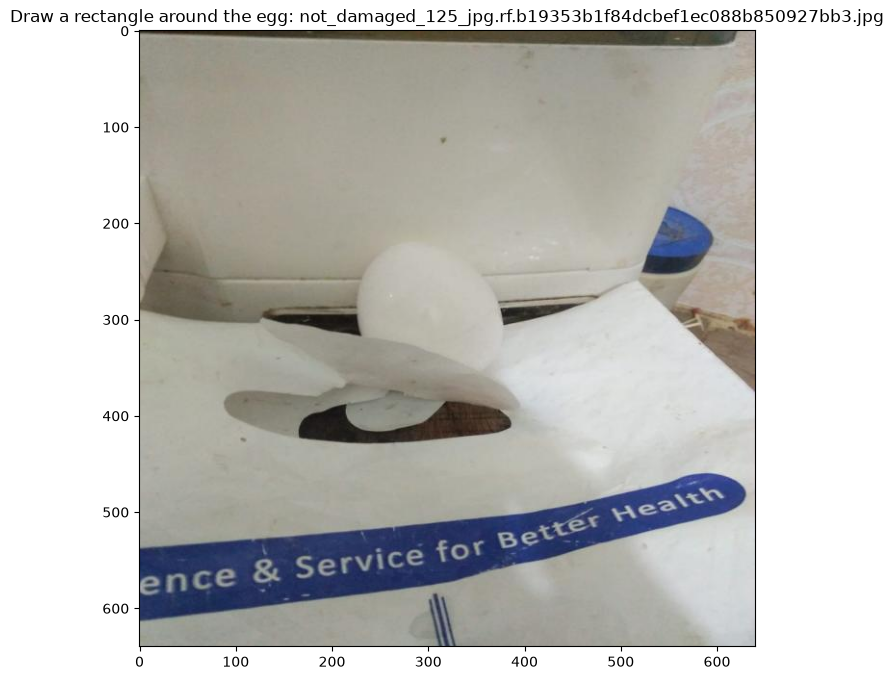

In [29]:
# Select one difficult test image
filename = df_grabcut_test.sort_values("IoU").iloc[1]["image"]
image_path = next(p for p in test_images if p.name == filename)

img_bgr = cv2.imread(str(image_path))
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# Display image so we can choose a rectangle around the egg
plt.figure(figsize=(8, 8))
plt.imshow(img_rgb)
plt.title(f"Draw a rectangle around the egg: {filename}")
plt.axis("on")
plt.show()

Rectangle GrabCut: IoU=0.7653, Dice=0.8671


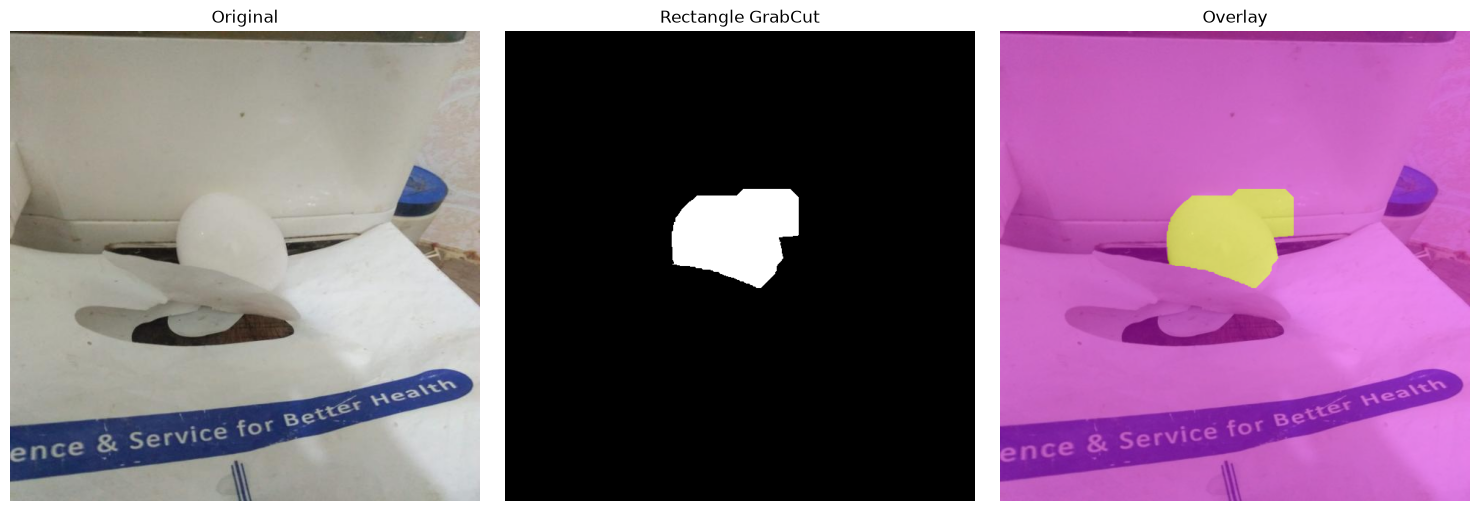

In [30]:
# Rectangle: (x, y, width, height)
# Includes the egg with some surrounding margin
rect = (220, 215, 180, 165)

grabcut_mask = np.zeros(img_bgr.shape[:2], dtype=np.uint8)
bg_model = np.zeros((1, 65), np.float64)
fg_model = np.zeros((1, 65), np.float64)

cv2.grabCut(
    img_bgr,
    grabcut_mask,
    rect,
    bg_model,
    fg_model,
    5,
    cv2.GC_INIT_WITH_RECT
)

grabcut_rect_result = np.isin(
    grabcut_mask,
    [cv2.GC_FGD, cv2.GC_PR_FGD]
).astype(np.uint8)

# Compare against the reference mask
stem = image_path.stem
mask_path = next(
    p for p in reference_masks
    if p.name.endswith(f"{stem}_combined.png")
)

reference = cv2.imread(
    str(mask_path), cv2.IMREAD_GRAYSCALE
) > 127

iou, dice = calculate_metrics(
    grabcut_rect_result, reference
)

print(f"Rectangle GrabCut: IoU={iou:.4f}, Dice={dice:.4f}")

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(grabcut_rect_result, cmap="gray")
plt.title("Rectangle GrabCut")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(img_rgb)
plt.imshow(grabcut_rect_result, cmap="spring", alpha=0.4)
plt.title("Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

Original GrabCut: IoU=0.7653
Cleaned GrabCut:  IoU=0.7653, Dice=0.8671


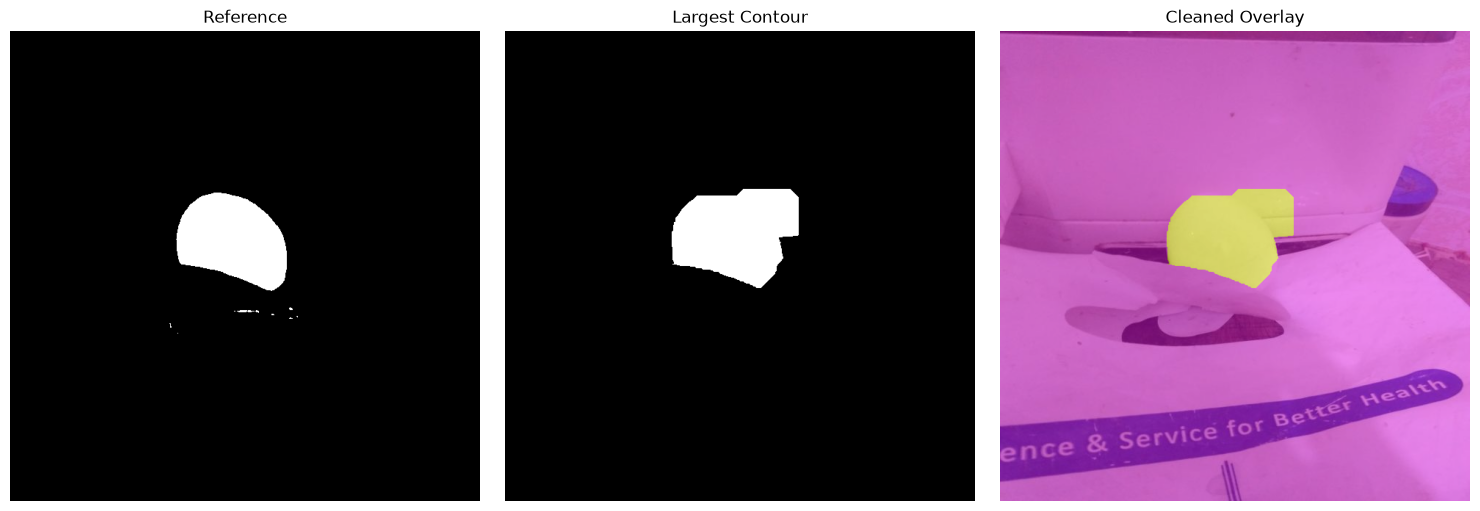

In [31]:
# Clean the rectangle GrabCut mask using contours
mask_uint8 = (grabcut_rect_result * 255).astype(np.uint8)

contours, _ = cv2.findContours(
    mask_uint8,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

cleaned_mask = np.zeros_like(mask_uint8)

if contours:
    largest_contour = max(contours, key=cv2.contourArea)
    cv2.drawContours(
        cleaned_mask, [largest_contour], -1, 255, thickness=cv2.FILLED
    )

iou, dice = calculate_metrics(
    cleaned_mask > 127, reference
)

print(f"Original GrabCut: IoU={calculate_metrics(grabcut_rect_result, reference)[0]:.4f}")
print(f"Cleaned GrabCut:  IoU={iou:.4f}, Dice={dice:.4f}")

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(reference, cmap="gray")
plt.title("Reference")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cleaned_mask, cmap="gray")
plt.title("Largest Contour")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(img_rgb)
plt.imshow(cleaned_mask, cmap="spring", alpha=0.4)
plt.title("Cleaned Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

Refined GrabCut: IoU=0.7659, Dice=0.8674


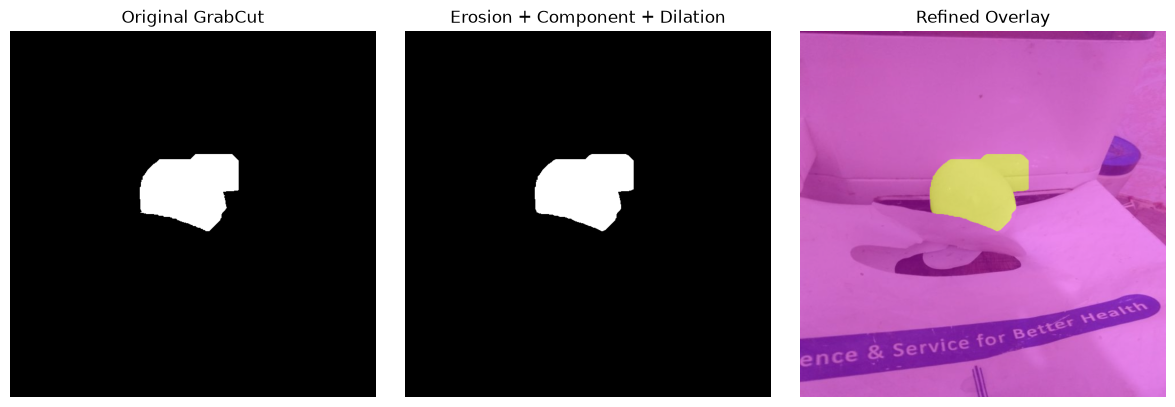

In [32]:
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))

# Shrink the mask to try to break narrow connections
eroded = cv2.erode(
    (grabcut_rect_result * 255).astype(np.uint8),
    kernel,
    iterations=2
)

# Keep the largest component
n, labels, stats, _ = cv2.connectedComponentsWithStats(
    (eroded > 127).astype(np.uint8), connectivity=8
)

if n > 1:
    largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    component = (labels == largest).astype(np.uint8) * 255
else:
    component = eroded

# Restore approximate size
refined = cv2.dilate(component, kernel, iterations=2)

iou, dice = calculate_metrics(refined > 127, reference)
print(f"Refined GrabCut: IoU={iou:.4f}, Dice={dice:.4f}")

plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(grabcut_rect_result, cmap="gray")
plt.title("Original GrabCut")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(refined, cmap="gray")
plt.title("Erosion + Component + Dilation")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(img_rgb)
plt.imshow(refined, cmap="spring", alpha=0.4)
plt.title("Refined Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

Convex Hull: IoU=0.7307, Dice=0.8444


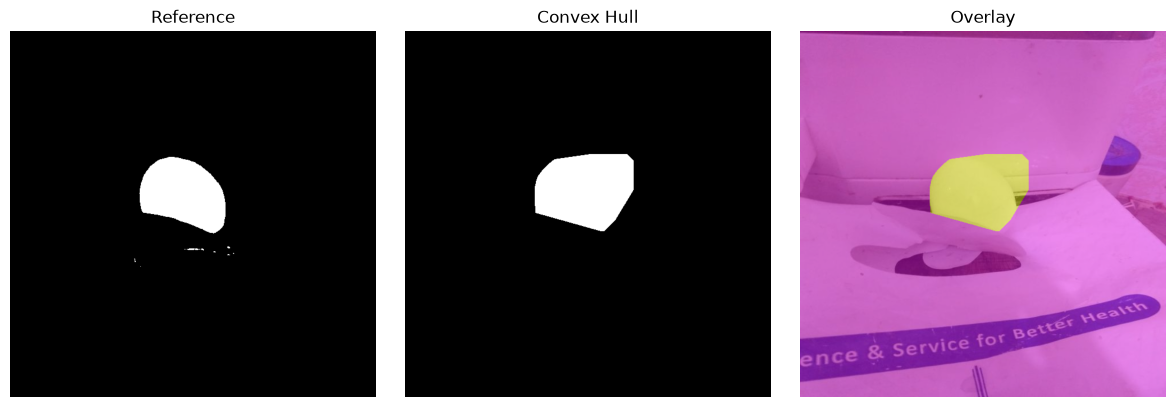

In [33]:
# Start with the rectangle-based GrabCut mask
mask = (grabcut_rect_result > 0).astype(np.uint8)

# Find the largest external contour
contours, _ = cv2.findContours(
    mask * 255,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

hull_mask = np.zeros_like(mask)

if contours:
    largest_contour = max(contours, key=cv2.contourArea)
    hull = cv2.convexHull(largest_contour)

    cv2.drawContours(
        hull_mask, [hull], -1, 1, thickness=cv2.FILLED
    )

iou, dice = calculate_metrics(hull_mask > 0, reference)

print(f"Convex Hull: IoU={iou:.4f}, Dice={dice:.4f}")

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(reference, cmap="gray")
plt.title("Reference")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(hull_mask, cmap="gray")
plt.title("Convex Hull")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(img_rgb)
plt.imshow(hull_mask, cmap="spring", alpha=0.4)
plt.title("Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

Convex hull made the shape less accurate: IoU dropped from 0.7653 to 0.7307. Let's keep the original rectangle GrabCut mask.
Next experiment: Evaluate rectangle GrabCut across the test set
Since you want a reasonably good result rather than perfection, let's use rectangle-based GrabCut on the test images with a simple automatic rectangle derived from the image center. This is only a heuristic; it may fail when eggs are off-center or overlap objects.

For now, we should not use manually selected rectangles as evidence of fully automatic segmentation. The rectangle experiment is useful for understanding GrabCut's potential, but the final method needs an automatic initialization

Watershed: IoU=0.0439, Dice=0.0841


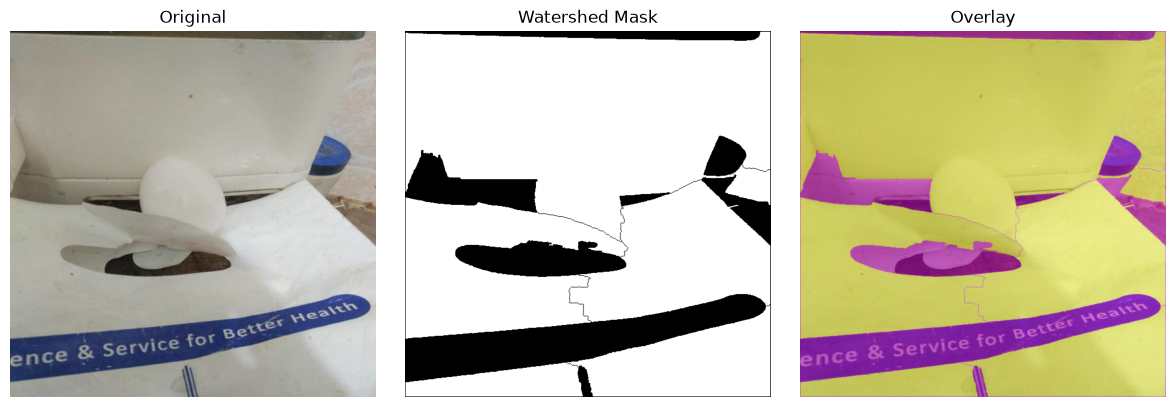

In [34]:
# Convert image to grayscale and apply Otsu thresholding
gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

_, thresh = cv2.threshold(
    gray, 0, 255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

# Remove noise and close small gaps
kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
opening = cv2.morphologyEx(
    thresh, cv2.MORPH_OPEN, kernel, iterations=2
)

# Identify sure background
sure_bg = cv2.dilate(opening, kernel, iterations=3)

# Identify sure foreground using distance transform
dist_transform = cv2.distanceTransform(
    opening, cv2.DIST_L2, 5
)

_, sure_fg = cv2.threshold(
    dist_transform,
    0.35 * dist_transform.max(),
    255,
    cv2.THRESH_BINARY
)

sure_fg = sure_fg.astype(np.uint8)

# Unknown region
unknown = cv2.subtract(sure_bg, sure_fg)

# Create markers for watershed
num_labels, markers = cv2.connectedComponents(sure_fg)
markers = markers + 1
markers[unknown == 255] = 0

# Apply watershed
markers = cv2.watershed(img_bgr.copy(), markers)

# Treat segmented foreground regions as the prediction
watershed_mask = (markers > 1).astype(np.uint8)

# Keep the largest connected component
n, labels, stats, _ = cv2.connectedComponentsWithStats(
    watershed_mask, connectivity=8
)

if n > 1:
    largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
    watershed_mask = (labels == largest).astype(np.uint8)

iou, dice = calculate_metrics(watershed_mask > 0, reference)

print(f"Watershed: IoU={iou:.4f}, Dice={dice:.4f}")

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(watershed_mask, cmap="gray")
plt.title("Watershed Mask")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(img_rgb)
plt.imshow(watershed_mask, cmap="spring", alpha=0.4)
plt.title("Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In [35]:
import pandas as pd
import numpy as np
import cv2

comparison_results = []

for image_path in test_images:
    stem = image_path.stem

    matching_masks = [
        p for p in reference_masks
        if p.name.endswith(f"{stem}_combined.png")
    ]

    if len(matching_masks) != 1:
        continue

    img_bgr = cv2.imread(str(image_path))
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    reference = cv2.imread(
        str(matching_masks[0]), cv2.IMREAD_GRAYSCALE
    ) > 127

    # ------------------------------------------------
    # Method 1: Otsu-initialized GrabCut
    # ------------------------------------------------
    _, otsu = cv2.threshold(
        gray, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    mask_otsu = np.where(
        otsu > 127, cv2.GC_PR_FGD, cv2.GC_PR_BGD
    ).astype(np.uint8)

    border = 10
    mask_otsu[:border, :] = cv2.GC_BGD
    mask_otsu[-border:, :] = cv2.GC_BGD
    mask_otsu[:, :border] = cv2.GC_BGD
    mask_otsu[:, -border:] = cv2.GC_BGD

    bg_model = np.zeros((1, 65), np.float64)
    fg_model = np.zeros((1, 65), np.float64)

    cv2.grabCut(
        img_bgr, mask_otsu, None,
        bg_model, fg_model, 5,
        cv2.GC_INIT_WITH_MASK
    )

    pred_otsu = np.isin(
        mask_otsu, [cv2.GC_FGD, cv2.GC_PR_FGD]
    )

    # Keep the largest component
    n, labels, stats, _ = cv2.connectedComponentsWithStats(
        pred_otsu.astype(np.uint8), connectivity=8
    )
    if n > 1:
        largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        pred_otsu = labels == largest

    iou_otsu, dice_otsu = calculate_metrics(pred_otsu, reference)

    # ------------------------------------------------
    # Method 2: Rectangle-initialized GrabCut
    # Fixed central rectangle, 60% image width/height
    # ------------------------------------------------
    h, w = gray.shape
    rw, rh = int(w * 0.60), int(h * 0.60)
    x, y = (w - rw) // 2, (h - rh) // 2
    rect = (x, y, rw, rh)

    mask_rect = np.zeros((h, w), dtype=np.uint8)
    bg_model = np.zeros((1, 65), np.float64)
    fg_model = np.zeros((1, 65), np.float64)

    cv2.grabCut(
        img_bgr, mask_rect, rect,
        bg_model, fg_model, 5,
        cv2.GC_INIT_WITH_RECT
    )

    pred_rect = np.isin(
        mask_rect, [cv2.GC_FGD, cv2.GC_PR_FGD]
    )

    n, labels, stats, _ = cv2.connectedComponentsWithStats(
        pred_rect.astype(np.uint8), connectivity=8
    )
    if n > 1:
        largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        pred_rect = labels == largest

    iou_rect, dice_rect = calculate_metrics(pred_rect, reference)

    comparison_results.append({
        "image": image_path.name,
        "Otsu_GrabCut_IoU": iou_otsu,
        "Otsu_GrabCut_Dice": dice_otsu,
        "Rectangle_GrabCut_IoU": iou_rect,
        "Rectangle_GrabCut_Dice": dice_rect
    })

df_comparison = pd.DataFrame(comparison_results)

print("Images evaluated:", len(df_comparison))
print("\nMean scores:")
display(df_comparison[
    [
        "Otsu_GrabCut_IoU",
        "Otsu_GrabCut_Dice",
        "Rectangle_GrabCut_IoU",
        "Rectangle_GrabCut_Dice"
    ]
].mean().to_frame("Mean score"))

print("\nPer-image results:")
display(df_comparison)

Images evaluated: 11

Mean scores:


,Mean score
Otsu_GrabCut_IoU,0.501365
Otsu_GrabCut_Dice,0.578227
Rectangle_GrabCut_IoU,0.539726
Rectangle_GrabCut_Dice,0.653731



Per-image results:


,image,Otsu_GrabCut_IoU,Otsu_GrabCut_Dice,Rectangle_GrabCut_IoU,Rectangle_GrabCut_Dice
0,not_damaged_101_jpg.rf.479d12a2b41a5ec6d718dcd...,0.988877,0.994407,0.954162,0.976543
1,not_damaged_125_jpg.rf.b19353b1f84dcbef1ec088b...,0.053898,0.102283,0.156893,0.271231
2,not_damaged_14_jpg.rf.dc96559078b03433d2b65e50...,0.908230,0.951908,0.245932,0.394777
3,not_damaged_152_jpg.rf.a57edb18d395ce87e23f7ab...,0.126179,0.224084,0.192497,0.322847
4,not_damaged_153_jpg.rf.ea842e70f08e63e69bbcc74...,0.300813,0.462500,0.504914,0.671021
5,not_damaged_161_jpg.rf.fd216aa5e11e147fc152747...,0.799436,0.888541,0.818996,0.900492
6,not_damaged_1_jpg.rf.d74c98a14f068b48c1f58fd57...,0.000000,0.000000,0.635184,0.776896
7,not_damaged_30_jpg.rf.48e9261777355fe67139ac1c...,0.176867,0.300573,0.727758,0.842430
8,not_damaged_43_jpg.rf.66c31342150e751c30214786...,0.860529,0.925037,0.827403,0.905551
9,not_damaged_4_jpg.rf.36c78b63ea4710d9642651ac3...,0.383976,0.554888,0.187343,0.315567


A fixed central rectangle is only a baseline. Let's improve it by estimating the egg's location using Otsu segmentation, then using the detected object's bounding box to initialize GrabCut.

In [36]:
def otsu_rectangle_grabcut(img_bgr):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    # Otsu thresholding
    _, otsu = cv2.threshold(
        gray, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Try both polarities; select the largest non-border component
    candidates = []

    for binary in [otsu, cv2.bitwise_not(otsu)]:
        cleaned = cv2.morphologyEx(
            binary,
            cv2.MORPH_OPEN,
            cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
        )

        n, labels, stats, _ = cv2.connectedComponentsWithStats(
            (cleaned > 127).astype(np.uint8), connectivity=8
        )

        h, w = gray.shape

        for i in range(1, n):
            x, y, bw, bh, area = stats[i]

            # Ignore tiny components and components touching image borders
            if area < 0.01 * h * w:
                continue
            if x == 0 or y == 0 or x + bw >= w or y + bh >= h:
                continue

            candidates.append((area, x, y, bw, bh))

    h, w = gray.shape

    if candidates:
        # Choose the largest eligible component
        _, x, y, bw, bh = max(candidates, key=lambda c: c[0])

        # Expand rectangle by 15% on each side
        pad_x = max(5, int(bw * 0.15))
        pad_y = max(5, int(bh * 0.15))

        x1 = max(0, x - pad_x)
        y1 = max(0, y - pad_y)
        x2 = min(w, x + bw + pad_x)
        y2 = min(h, y + bh + pad_y)

        rect = (x1, y1, x2 - x1, y2 - y1)
    else:
        # Fallback to a central rectangle
        rw, rh = int(w * 0.60), int(h * 0.60)
        rect = ((w - rw) // 2, (h - rh) // 2, rw, rh)

    mask = np.zeros((h, w), dtype=np.uint8)
    bg_model = np.zeros((1, 65), np.float64)
    fg_model = np.zeros((1, 65), np.float64)

    cv2.grabCut(
        img_bgr, mask, rect,
        bg_model, fg_model, 5,
        cv2.GC_INIT_WITH_RECT
    )

    prediction = np.isin(
        mask, [cv2.GC_FGD, cv2.GC_PR_FGD]
    ).astype(np.uint8)

    # Keep the largest predicted component
    n, labels, stats, _ = cv2.connectedComponentsWithStats(
        prediction, connectivity=8
    )

    if n > 1:
        largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        prediction = (labels == largest).astype(np.uint8)

    return prediction

In [37]:
auto_rect_results = []

for image_path in test_images:
    stem = image_path.stem

    matches = [
        p for p in reference_masks
        if p.name.endswith(f"{stem}_combined.png")
    ]

    if len(matches) != 1:
        continue

    img_bgr = cv2.imread(str(image_path))
    reference = cv2.imread(
        str(matches[0]), cv2.IMREAD_GRAYSCALE
    ) > 127

    prediction = otsu_rectangle_grabcut(img_bgr)

    iou, dice = calculate_metrics(prediction > 0, reference)

    auto_rect_results.append({
        "image": image_path.name,
        "IoU": iou,
        "Dice": dice
    })

df_auto_rect = pd.DataFrame(auto_rect_results)

print("Images evaluated:", len(df_auto_rect))
print(f"Mean IoU:  {df_auto_rect['IoU'].mean():.4f}")
print(f"Mean Dice: {df_auto_rect['Dice'].mean():.4f}")
print(f"Median IoU:  {df_auto_rect['IoU'].median():.4f}")
print(f"Median Dice: {df_auto_rect['Dice'].median():.4f}")

Images evaluated: 11
Mean IoU:  0.5294
Mean Dice: 0.6076
Median IoU:  0.5896
Median Dice: 0.7418


Visualize the worst results

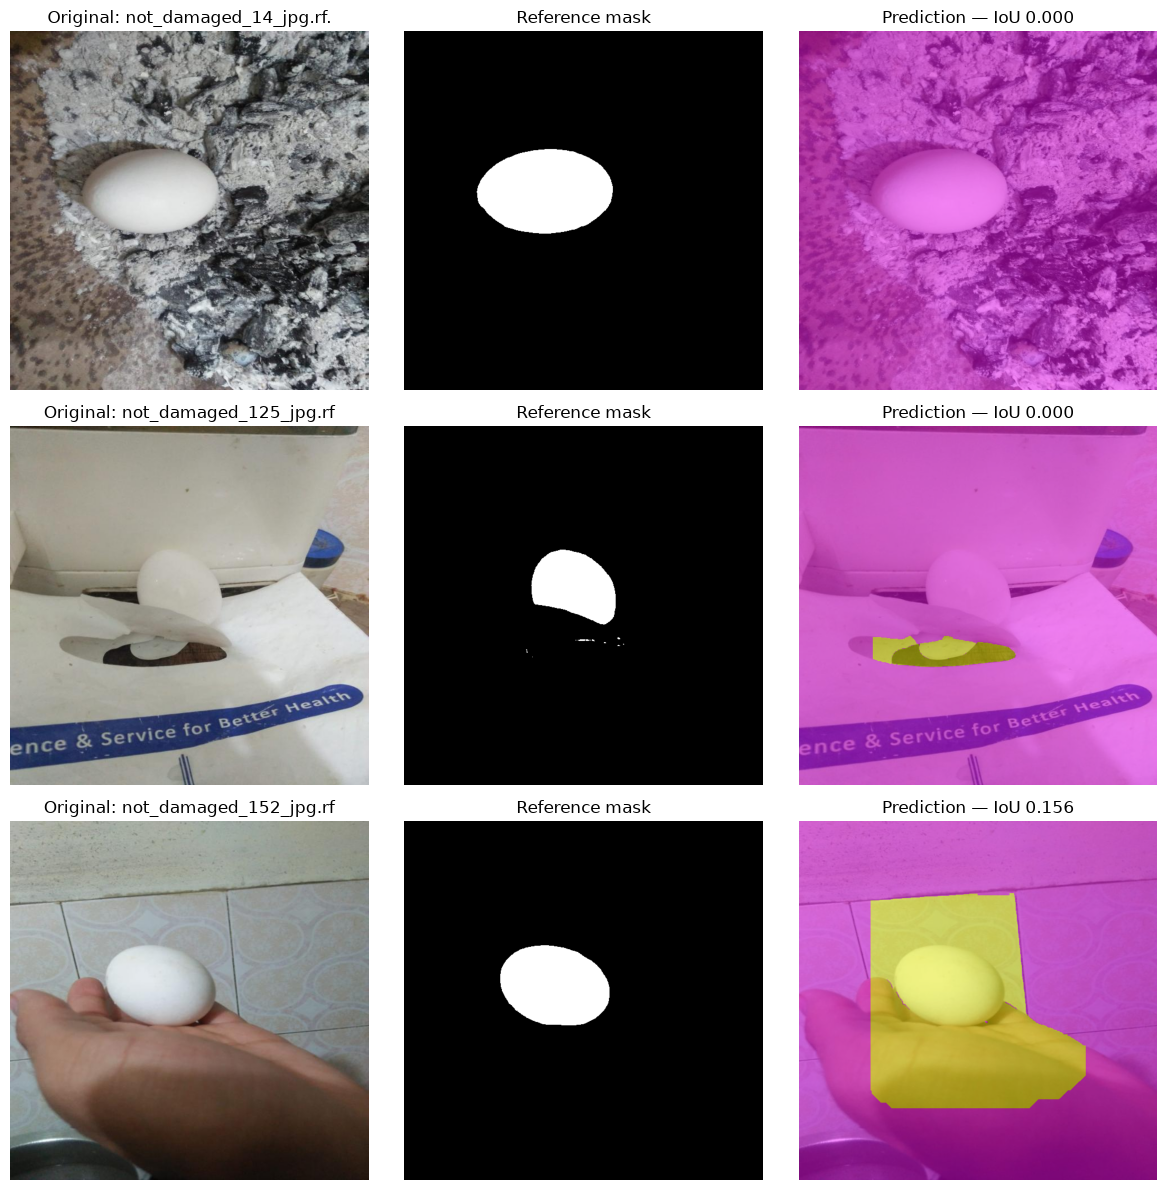

In [38]:
# Display the 3 worst automatic-rectangle results
worst = df_auto_rect.nsmallest(3, "IoU")

fig, axes = plt.subplots(len(worst), 3, figsize=(12, 4 * len(worst)))

if len(worst) == 1:
    axes = np.array([axes])

for row, (_, result) in enumerate(worst.iterrows()):
    image_path = next(
        p for p in test_images if p.name == result["image"]
    )

    mask_path = next(
        p for p in reference_masks
        if p.name.endswith(f"{image_path.stem}_combined.png")
    )

    img_bgr = cv2.imread(str(image_path))
    prediction = otsu_rectangle_grabcut(img_bgr)
    reference = cv2.imread(str(mask_path), cv2.IMREAD_GRAYSCALE) > 127
    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

    axes[row, 0].imshow(img_rgb)
    axes[row, 0].set_title(f"Original: {image_path.stem[:22]}")

    axes[row, 1].imshow(reference, cmap="gray")
    axes[row, 1].set_title("Reference mask")

    axes[row, 2].imshow(img_rgb)
    axes[row, 2].imshow(prediction, cmap="spring", alpha=0.45)
    axes[row, 2].set_title(f"Prediction — IoU {result['IoU']:.3f}")

    for ax in axes[row]:
        ax.axis("off")

plt.tight_layout()
plt.show()

The automatic rectangle method is failing on some images, especially when the background or another object gets included in the mask

Evaluate Lab b Inverse + Morphology

In [39]:
lab_results = []

kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))

for image_path in test_images:
    matches = [
        p for p in reference_masks
        if p.name.endswith(f"{image_path.stem}_combined.png")
    ]

    if len(matches) != 1:
        continue

    img_bgr = cv2.imread(str(image_path))
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)

    # Extract the Lab b channel
    b_channel = lab[:, :, 2]

    # Inverse Otsu thresholding
    _, prediction = cv2.threshold(
        b_channel, 0, 255,
        cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
    )

    # Morphological opening removes small noise
    prediction = cv2.morphologyEx(
        prediction, cv2.MORPH_OPEN, kernel
    )

    # Closing fills small gaps
    prediction = cv2.morphologyEx(
        prediction, cv2.MORPH_CLOSE, kernel
    )

    # Keep the largest connected component
    n, labels, stats, _ = cv2.connectedComponentsWithStats(
        (prediction > 0).astype(np.uint8), connectivity=8
    )

    if n > 1:
        largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        prediction = (labels == largest).astype(np.uint8)
    else:
        prediction = np.zeros(prediction.shape, dtype=np.uint8)

    reference = cv2.imread(
        str(matches[0]), cv2.IMREAD_GRAYSCALE
    ) > 127

    iou, dice = calculate_metrics(prediction > 0, reference)

    lab_results.append({
        "image": image_path.name,
        "IoU": iou,
        "Dice": dice
    })

df_lab = pd.DataFrame(lab_results)

print("Images evaluated:", len(df_lab))
print(f"Mean IoU:    {df_lab['IoU'].mean():.4f}")
print(f"Mean Dice:   {df_lab['Dice'].mean():.4f}")
print(f"Median IoU:  {df_lab['IoU'].median():.4f}")
print(f"Median Dice: {df_lab['Dice'].median():.4f}")

Images evaluated: 11
Mean IoU:    0.2509
Mean Dice:   0.3168
Median IoU:  0.0989
Median Dice: 0.1799


drop Lab b. It performed well on one image but doesn't generalize across the test set.
Our next experiment should be a better approach to GrabCut, rather than trying more thresholding methods

test GrabCut initialized with a foreground seed from the Otsu mask and a background seed from the image borders.

In [40]:
def seeded_grabcut(img_bgr):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    h, w = gray.shape

    # Otsu thresholding
    _, otsu = cv2.threshold(
        gray, 0, 255,
        cv2.THRESH_BINARY + cv2.THRESH_OTSU
    )

    # Try both polarities and select the one with the
    # largest non-border connected component.
    candidates = []

    for binary in [otsu, cv2.bitwise_not(otsu)]:
        binary = cv2.morphologyEx(
            binary,
            cv2.MORPH_OPEN,
            cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
        )

        n, labels, stats, _ = cv2.connectedComponentsWithStats(
            (binary > 0).astype(np.uint8), connectivity=8
        )

        for i in range(1, n):
            x, y, bw, bh, area = stats[i]

            if area < 0.01 * h * w:
                continue

            if x == 0 or y == 0 or x + bw >= w or y + bh >= h:
                continue

            candidates.append((area, labels == i))

    if not candidates:
        # Fall back to a central rectangle if no candidate is found
        rw, rh = int(w * 0.6), int(h * 0.6)
        rect = ((w - rw) // 2, (h - rh) // 2, rw, rh)

        mask = np.zeros((h, w), np.uint8)
        bg_model = np.zeros((1, 65), np.float64)
        fg_model = np.zeros((1, 65), np.float64)

        cv2.grabCut(
            img_bgr, mask, rect, bg_model, fg_model, 5,
            cv2.GC_INIT_WITH_RECT
        )

    else:
        _, foreground = max(candidates, key=lambda item: item[0])

        # Start with probable background everywhere
        mask = np.full((h, w), cv2.GC_PR_BGD, dtype=np.uint8)

        # Use the detected component as probable foreground
        mask[foreground] = cv2.GC_PR_FGD

        # Erode the component to obtain a definite foreground seed
        fg_seed = cv2.erode(
            foreground.astype(np.uint8),
            cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5)),
            iterations=2
        )
        mask[fg_seed > 0] = cv2.GC_FGD

        # Mark image borders as definite background
        border = 5
        mask[:border, :] = cv2.GC_BGD
        mask[-border:, :] = cv2.GC_BGD
        mask[:, :border] = cv2.GC_BGD
        mask[:, -border:] = cv2.GC_BGD

        bg_model = np.zeros((1, 65), np.float64)
        fg_model = np.zeros((1, 65), np.float64)

        cv2.grabCut(
            img_bgr, mask, None, bg_model, fg_model, 5,
            cv2.GC_INIT_WITH_MASK
        )

    prediction = np.isin(
        mask, [cv2.GC_FGD, cv2.GC_PR_FGD]
    ).astype(np.uint8)

    # Keep the largest connected component
    n, labels, stats, _ = cv2.connectedComponentsWithStats(
        prediction, connectivity=8
    )

    if n > 1:
        largest = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        prediction = (labels == largest).astype(np.uint8)

    return prediction

In [41]:
seeded_results = []

for image_path in test_images:
    matches = [
        p for p in reference_masks
        if p.name.endswith(f"{image_path.stem}_combined.png")
    ]

    if len(matches) != 1:
        continue

    img_bgr = cv2.imread(str(image_path))
    reference = cv2.imread(
        str(matches[0]), cv2.IMREAD_GRAYSCALE
    ) > 127

    prediction = seeded_grabcut(img_bgr)

    iou, dice = calculate_metrics(prediction > 0, reference)

    seeded_results.append({
        "image": image_path.name,
        "IoU": iou,
        "Dice": dice
    })

df_seeded = pd.DataFrame(seeded_results)

print("Images evaluated:", len(df_seeded))
print(f"Mean IoU:   {df_seeded['IoU'].mean():.4f}")
print(f"Mean Dice:  {df_seeded['Dice'].mean():.4f}")
print(f"Median IoU: {df_seeded['IoU'].median():.4f}")
print(f"Median Dice:{df_seeded['Dice'].median():.4f}")

Images evaluated: 11
Mean IoU:   0.4486
Mean Dice:  0.5041
Median IoU: 0.1925
Median Dice:0.3228


Edge-guided segmentation:
Instead of relying on brightness thresholds, we'll try Canny edge detection + contour selection. The idea is to detect the egg's boundary and fill the enclosed contour to create a mask.

In [42]:
def canny_segmentation(img_bgr):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    # Smooth small image variations
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # Detect edges
    edges = cv2.Canny(blurred, 50, 150)

    # Close gaps in egg boundaries
    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (5, 5)
    )
    closed = cv2.morphologyEx(
        edges, cv2.MORPH_CLOSE, kernel, iterations=2
    )

    # Find external contours
    contours, _ = cv2.findContours(
        closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    prediction = np.zeros(gray.shape, dtype=np.uint8)

    if contours:
        # Select the largest contour
        largest = max(contours, key=cv2.contourArea)
        cv2.drawContours(
            prediction, [largest], -1, 1, cv2.FILLED
        )

    return prediction


canny_results = []

for image_path in test_images:
    matches = [
        p for p in reference_masks
        if p.name.endswith(f"{image_path.stem}_combined.png")
    ]

    if len(matches) != 1:
        continue

    img_bgr = cv2.imread(str(image_path))
    reference = cv2.imread(
        str(matches[0]), cv2.IMREAD_GRAYSCALE
    ) > 127

    prediction = canny_segmentation(img_bgr)

    iou, dice = calculate_metrics(prediction > 0, reference)

    canny_results.append({
        "image": image_path.name,
        "IoU": iou,
        "Dice": dice
    })

df_canny = pd.DataFrame(canny_results)

print("Images evaluated:", len(df_canny))
print(f"Mean IoU:   {df_canny['IoU'].mean():.4f}")
print(f"Mean Dice:  {df_canny['Dice'].mean():.4f}")
print(f"Median IoU: {df_canny['IoU'].median():.4f}")
print(f"Median Dice:{df_canny['Dice'].median():.4f}")

Images evaluated: 11
Mean IoU:   0.0483
Mean Dice:  0.0761
Median IoU: 0.0006
Median Dice:0.0013


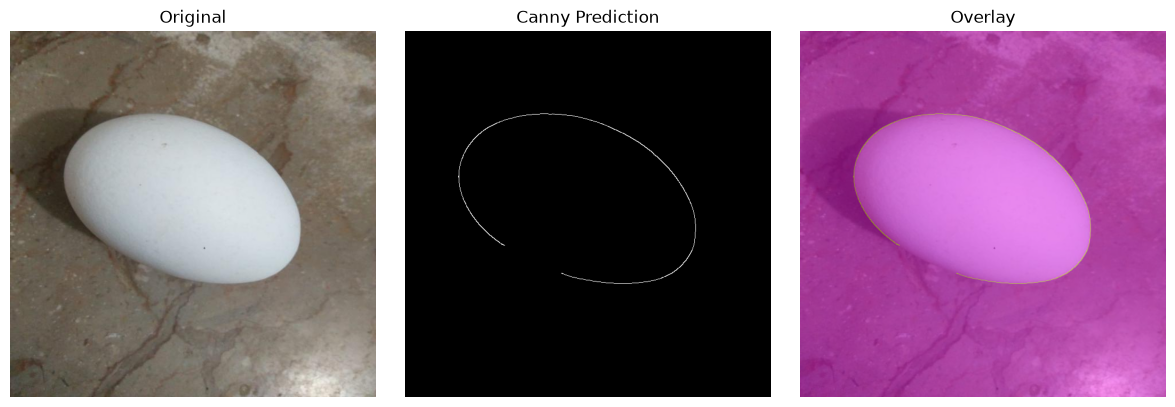

In [43]:
sample_path = test_images[0]
sample_bgr = cv2.imread(str(sample_path))
sample_rgb = cv2.cvtColor(sample_bgr, cv2.COLOR_BGR2RGB)

sample_pred = canny_segmentation(sample_bgr)

sample_mask_path = next(
    p for p in reference_masks
    if p.name.endswith(f"{sample_path.stem}_combined.png")
)
sample_ref = cv2.imread(
    str(sample_mask_path), cv2.IMREAD_GRAYSCALE
) > 127

plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(sample_rgb)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(sample_pred, cmap="gray")
plt.title("Canny Prediction")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(sample_rgb)
plt.imshow(sample_pred, cmap="spring", alpha=0.4)
plt.title("Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

he edge detects the egg boundary, but it leaves a small gap. We can close the gap and fill the enclosed contour using cv2.drawContours(..., cv2.FILLED)

In [44]:
def canny_segmentation(img_bgr):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)

    # Detect edges
    edges = cv2.Canny(blurred, 50, 150)

    # Close small gaps in the egg boundary
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    closed = cv2.morphologyEx(
        edges, cv2.MORPH_CLOSE, kernel, iterations=3
    )

    # Find external contours
    contours, _ = cv2.findContours(
        closed, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE
    )

    # Create a binary mask: background = 0, egg = 1
    prediction = np.zeros(gray.shape, dtype=np.uint8)

    if contours:
        largest = max(contours, key=cv2.contourArea)
        cv2.drawContours(
            prediction, [largest], -1, color=1, thickness=cv2.FILLED
        )

    return prediction


In [45]:
print("Canny Segmentation — Test Set")
print(f"Images evaluated: {len(df_canny)}")
print(f"Mean IoU:   {df_canny['IoU'].mean():.4f}")
print(f"Mean Dice:  {df_canny['Dice'].mean():.4f}")
print(f"Median IoU: {df_canny['IoU'].median():.4f}")
print(f"Median Dice:{df_canny['Dice'].median():.4f}")

display(df_canny.sort_values("IoU"))


Canny Segmentation — Test Set
Images evaluated: 11
Mean IoU:   0.0483
Mean Dice:  0.0761
Median IoU: 0.0006
Median Dice:0.0013


,image,IoU,Dice
1,not_damaged_125_jpg.rf.b19353b1f84dcbef1ec088b...,0.000000,0.000000
4,not_damaged_153_jpg.rf.ea842e70f08e63e69bbcc74...,0.000000,0.000000
7,not_damaged_30_jpg.rf.48e9261777355fe67139ac1c...,0.000000,0.000000
8,not_damaged_43_jpg.rf.66c31342150e751c30214786...,0.000000,0.000000
9,not_damaged_4_jpg.rf.36c78b63ea4710d9642651ac3...,0.000000,0.000000
2,not_damaged_14_jpg.rf.dc96559078b03433d2b65e50...,0.000632,0.001263
0,not_damaged_101_jpg.rf.479d12a2b41a5ec6d718dcd...,0.001234,0.002464
5,not_damaged_161_jpg.rf.fd216aa5e11e147fc152747...,0.007481,0.014851
6,not_damaged_1_jpg.rf.d74c98a14f068b48c1f58fd57...,0.009862,0.019531
10,not_damaged_78_jpg.rf.d3a6e8624d192abc58ff7df9...,0.166662,0.285707


We experimented with several classical computer vision methods for egg segmentation, including Otsu thresholding, HSV-based thresholding, K-means clustering, watershed, Canny edge detection, and different GrabCut initialization strategies.

Among the methods evaluated on the 11-image test split, fixed-rectangle GrabCut achieved the best aggregate performance, with a mean IoU of 0.5397 and a mean Dice score of 0.6537. Otsu-initialized GrabCut was another competitive approach, but its overall performance was lower.

Canny edge detection performed poorly because the detected boundaries did not consistently produce suitable egg masks. Thresholding and clustering methods also struggled with variations in egg colour, lighting, and background appearance.

Therefore, fixed-rectangle GrabCut was selected as the best-performing classical baseline among the methods tested. The reference masks were generated using DINO+SAM, so these metrics measure agreement with those reference masks rather than accuracy against manually verified ground truth.

# Inspect the video

In [52]:
import cv2

video_path = "/home/mohsinkhan/Egg/data/Raw-and-Boiled-SnapYT.App.mp4"

cap = cv2.VideoCapture(video_path)

print("Opened:", cap.isOpened())

ret, frame = cap.read()
print("Frame extracted:", ret)

if ret:
    print("Frame shape:", frame.shape)

cap.release()

Opened: True
Frame extracted: True
Frame shape: (360, 640, 3)
